# 02 — `random`, `statistics`, `collections` (Simulasi & Statistik Ringan)
**Mata Kuliah:** Probabilitas dan Statistika | **Nama / NIM:** ________

Fokus: **simulasi Monte Carlo** dan statistik deskriptif memakai pustaka standar. `statistics.NormalDist` memberi distribusi normal lengkap (PDF, CDF, kuantil) tanpa SciPy.

## 1. Eksplorasi Library
| Library | Fungsi utama | Kegunaan |
|---|---|---|
| `random` | `seed`, `random`, `randint`, `choice`, `choices(weights=)`, `sample`, `shuffle`, `gauss`, `expovariate`, `betavariate`, `triangular` | Pembangkit bilangan acak & sampel dari berbagai distribusi |
| `statistics` | `mean`, `fmean`, `median`, `mode`, `multimode`, `variance`, `pvariance`, `stdev`, `pstdev`, `quantiles`, `correlation`, `covariance` | Statistik deskriptif |
| `statistics.NormalDist` | `pdf`, `cdf`, `inv_cdf`, `zscore`, `overlap`, `samples` | Distribusi Normal |
| `collections.Counter` | `Counter`, `most_common` | Tabel frekuensi → estimasi PMF empiris |

In [1]:
import random, math, statistics as st
from collections import Counter
from statistics import NormalDist
import matplotlib.pyplot as plt

random.seed(42)
data=[random.randint(1,6) for _ in range(20)]
print("data       :", data)
print("mean/median:", st.mean(data), st.median(data), "| modus:", st.multimode(data))
print("var sampel :", round(st.variance(data),3), "| var populasi:", round(st.pvariance(data),3))
print("stdev      :", round(st.stdev(data),3))
print("kuartil    :", st.quantiles(data, n=4))
print("Counter    :", Counter(data).most_common(3))
print("choices berbobot:", random.choices(['A','B','C'], weights=[0.7,0.2,0.1], k=10))

data       : [6, 1, 1, 6, 3, 2, 2, 2, 6, 1, 6, 6, 5, 1, 5, 4, 1, 1, 1, 2]
mean/median: 3.1 2.0 | modus: [1]
var sampel : 4.516 | var populasi: 4.29
stdev      : 2.125
kuartil    : [1.0, 2.0, 5.75]
Counter    : [(1, 7), (6, 5), (2, 4)]
choices berbobot: ['A', 'A', 'A', 'B', 'B', 'A', 'A', 'A', 'B', 'B']


## 2. Implementasi pada Permasalahan Probabilitas
### Soal 2.1 — Monty Hall
Tiga pintu, satu berisi hadiah. Peserta memilih satu, pembawa acara membuka pintu kosong lain. Apakah lebih baik **tetap** atau **ganti**?
**Manual:** tetap → 1/3; ganti → 2/3.

In [2]:
def monty(ganti, N=100_000):
    menang=0
    for _ in range(N):
        hadiah=random.randrange(3); pilih=random.randrange(3)
        buka=random.choice([d for d in range(3) if d!=pilih and d!=hadiah])
        if ganti: pilih=next(d for d in range(3) if d!=pilih and d!=buka)
        menang += (pilih==hadiah)
    return menang/N
random.seed(1)
print("Tetap :", monty(False), "(teori 0.3333)")
print("Ganti :", monty(True),  "(teori 0.6667)")

Tetap : 0.3354 (teori 0.3333)


Ganti : 0.66677 (teori 0.6667)


**Interpretasi:** Mengganti pintu menggandakan peluang menang. Pembawa acara tidak membuka pintu secara acak (ia tahu isinya), sehingga informasi tambahan "terkonsentrasi" pada pintu yang tersisa — contoh klasik probabilitas bersyarat.

### Soal 2.2 — Paradoks ulang tahun (simulasi vs eksak)
Dalam kelas n orang, berapa P(ada minimal dua orang berulang tahun sama)? Eksak: 1 − ∏(365−i)/365.

  n    eksak  simulasi


 10   0.1169    0.1134


 20   0.4114    0.4107
 23   0.5073    0.5105


 30   0.7063    0.7036


 40   0.8912    0.8878


 50   0.9704    0.9716


 60   0.9941    0.9940


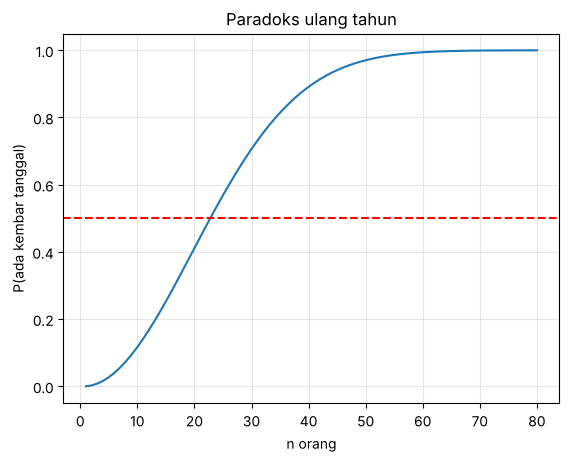

In [3]:
def exact(n): return 1-math.prod((365-i)/365 for i in range(n))
def sim(n,N=20_000): return sum(len(set(random.randrange(365) for _ in range(n)))<n for _ in range(N))/N
random.seed(5)
print(f"{'n':>3} {'eksak':>8} {'simulasi':>9}")
ns=[10,20,23,30,40,50,60]
for n in ns: print(f"{n:>3} {exact(n):8.4f} {sim(n):9.4f}")
plt.plot(range(1,81),[exact(n) for n in range(1,81)]); plt.axhline(.5,ls='--',c='r')
plt.xlabel("n orang"); plt.ylabel("P(ada kembar tanggal)"); plt.title("Paradoks ulang tahun"); plt.grid(alpha=.3); plt.show()

**Interpretasi:** Dengan hanya **23 orang** peluang sudah ±50,7%, dan 50 orang ±97%. Ini setara dengan **tabrakan hash (hash collision)**: untuk ruang hash berukuran M, tabrakan mulai sering muncul setelah ±√M entri (*birthday attack*).

### Soal 2.3 — Hukum Bilangan Besar & estimasi π
(a) Lempar koin adil; rata-rata proporsi "gambar" menuju 0,5. (b) Titik acak (x,y) pada [0,1]²; proporsi yang jatuh di dalam seperempat lingkaran ≈ π/4.

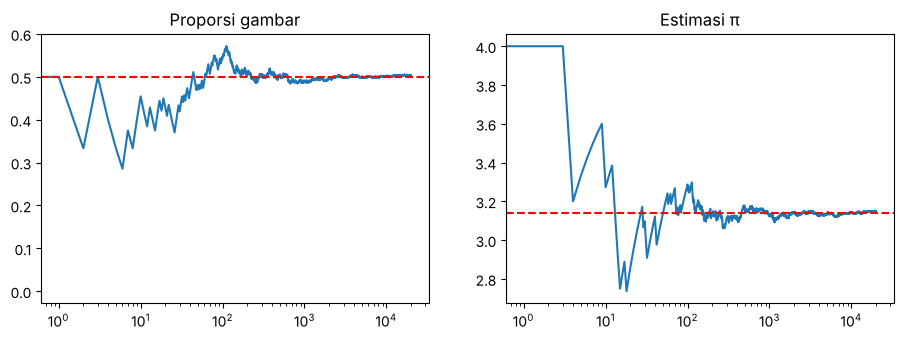

proporsi akhir = 0.50395  | estimasi pi = 3.149  | selisih = 0.007407346410206905


In [4]:
random.seed(10)
N=20_000
s=0; run=[]
for i in range(1,N+1):
    s+=random.random()<0.5; run.append(s/i)
inside=0; est=[]
for i in range(1,N+1):
    x,y=random.random(),random.random(); inside+= x*x+y*y<=1; est.append(4*inside/i)
fig,ax=plt.subplots(1,2,figsize=(11,3.5))
ax[0].plot(run); ax[0].axhline(.5,c='r',ls='--'); ax[0].set_title("Proporsi gambar"); ax[0].set_xscale('log')
ax[1].plot(est); ax[1].axhline(math.pi,c='r',ls='--'); ax[1].set_title("Estimasi π"); ax[1].set_xscale('log')
plt.show()
print("proporsi akhir =",run[-1]," | estimasi pi =",est[-1]," | selisih =",abs(est[-1]-math.pi))

**Interpretasi:** Fluktuasi besar di awal mengecil seiring N bertambah (galat ∝ 1/√N). Untuk gain 1 digit desimal ekstra dibutuhkan ±100× lebih banyak sampel — itulah kelemahan Monte Carlo.

### Soal 2.4 — Teorema Bayes: alarm IDS (base-rate fallacy)
Sebuah IDS mendeteksi serangan dengan sensitivitas 99% dan false positive 5%. Hanya 1% lalu lintas adalah serangan. Jika alarm berbunyi, berapa peluang itu benar-benar serangan?
**Manual:** (0,01·0,99)/(0,01·0,99+0,99·0,05)=0,0099/0,0594=**1/6 ≈ 0,1667**.

In [5]:
prior,tpr,fpr=0.01,0.99,0.05
post=prior*tpr/(prior*tpr+(1-prior)*fpr)
print("Posterior teori:", round(post,4))
random.seed(2)
alarm=benar=0
for _ in range(1_000_000):
    serang=random.random()<prior
    a = random.random()<(tpr if serang else fpr)
    if a: alarm+=1; benar+=serang
print("Simulasi       :", round(benar/alarm,4), f"({benar} dari {alarm} alarm)")

Posterior teori: 0.1667


Simulasi       : 0.166 (9864 dari 59417 alarm)


**Interpretasi:** Meskipun IDS "99% akurat", hanya ±1 dari 6 alarm yang benar. Penyebabnya **base rate rendah**: serangan jarang, sehingga false positive (5% dari trafik normal yang sangat banyak) mendominasi. Pelajaran: akurasi sensor harus dibaca bersama prevalensi.

## 3. Implementasi pada Distribusi Probabilitas
### Soal 3.1 — Normal (`NormalDist`): latensi server
Latensi ~ N(μ=200 ms, σ=30 ms). Hitung P(X>250), P(170<X<230), persentil ke-95, z-score untuk 260 ms.

P(X>250)       = 0.0478
P(170<X<230)   = 0.6827 (aturan 68%)
P95            = 249.35 ms
z(260)         = 2.0
pdf(200)       = 0.0133
mean sampel    = 199.94  stdev = 29.99


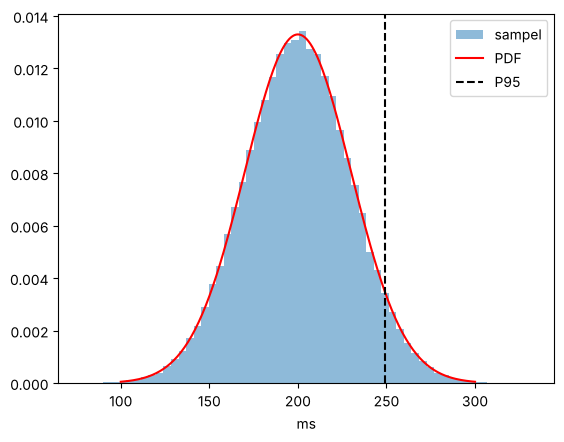

In [6]:
X=NormalDist(mu=200,sigma=30)
print("P(X>250)       =", round(1-X.cdf(250),4))
print("P(170<X<230)   =", round(X.cdf(230)-X.cdf(170),4), "(aturan 68%)")
print("P95            =", round(X.inv_cdf(0.95),2),"ms")
print("z(260)         =", round(X.zscore(260),2))
print("pdf(200)       =", round(X.pdf(200),5))
random.seed(3)
s=X.samples(100_000, seed=3)
print("mean sampel    =", round(st.fmean(s),2)," stdev =",round(st.stdev(s),2))
xs=[100+i for i in range(201)]
plt.hist(s,bins=60,density=True,alpha=.5,label="sampel"); plt.plot(xs,[X.pdf(x) for x in xs],'r',label="PDF")
plt.axvline(X.inv_cdf(.95),c='k',ls='--',label="P95"); plt.xlabel("ms"); plt.legend(); plt.show()

**Interpretasi:** ±4,8% permintaan lebih lambat dari 250 ms; 95% permintaan selesai di bawah ±249 ms (nilai ini dipakai sebagai target SLA). Rentang μ±σ memuat ±68,3% data. Sampel simulasi cocok dengan kurva PDF.

### Soal 3.2 — Eksponensial & proses Poisson (dibangkitkan dengan `expovariate`)
Request tiba dengan laju λ=4/detik. Waktu antar-kedatangan ~ Exp(λ). 
**Manual:** E[T]=1/λ=0,25 dtk; P(T>0,5)=e^(−λt)=e^(−2)≈0,1353. Jumlah kedatangan per detik ~ Poisson(4).

E[T] simulasi: 0.2489 | inverse-transform: 0.2489 | teori 0.25
P(T>0.5) sim : 0.1357 | teori 0.1353
mean = 3.996  var = 3.985 (Poisson: keduanya 4)


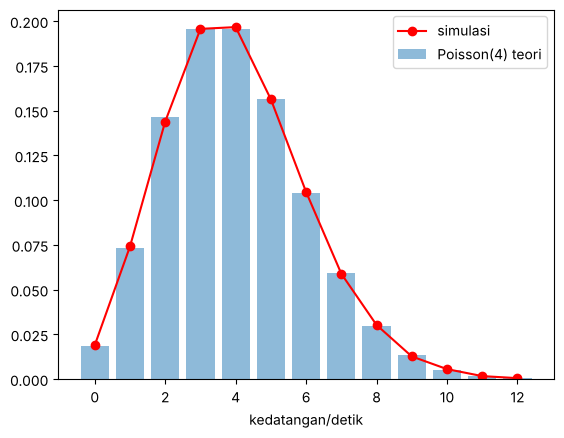

In [7]:
lam=4
random.seed(8)
T=[random.expovariate(lam) for _ in range(100_000)]
# inverse transform manual: T = -ln(U)/lam
T2=[-math.log(1-random.random())/lam for _ in range(100_000)]
print("E[T] simulasi:", round(st.fmean(T),4), "| inverse-transform:", round(st.fmean(T2),4), "| teori 0.25")
print("P(T>0.5) sim :", round(sum(t>0.5 for t in T)/len(T),4), "| teori", round(math.exp(-lam*0.5),4))

# hitung kedatangan per detik pada proses Poisson
def kedatangan():
    t=0;k=0
    while True:
        t+=random.expovariate(lam)
        if t>1: return k
        k+=1
hit=[kedatangan() for _ in range(50_000)]
c=Counter(hit)
pois=lambda k: math.exp(-lam)*lam**k/math.factorial(k)
print("mean =",round(st.fmean(hit),3)," var =",round(st.pvariance(hit),3),"(Poisson: keduanya 4)")
ks=range(0,13)
plt.bar(ks,[pois(k) for k in ks],alpha=.5,label="Poisson(4) teori"); plt.plot(ks,[c[k]/len(hit) for k in ks],'ro-',label="simulasi")
plt.legend(); plt.xlabel("kedatangan/detik"); plt.show()

**Interpretasi:** Waktu antar-kedatangan eksponensial menghasilkan jumlah kedatangan Poisson — dua sisi dari proses yang sama. Mean ≈ varians ≈ 4 menegaskan ciri Poisson. Eksponensial bersifat **tanpa-ingatan** (memoryless): sudah menunggu berapa lama pun, sisa waktu tunggu tetap berdistribusi sama.

### Soal 3.3 — Binomial, Geometrik dan Uniform dari `random`
Demonstrasi tiga distribusi diskrit lewat simulasi dan perbandingan dengan nilai harapan teori.

Binomial(20,.3): mean 5.997 (6)   var 4.189 (4.2)
Geometrik(.25) : mean 4.019 (4)   var 11.97 (12)
Uniform(1..6)  : mean 3.493 (3.5) var 2.902 (2.9167)


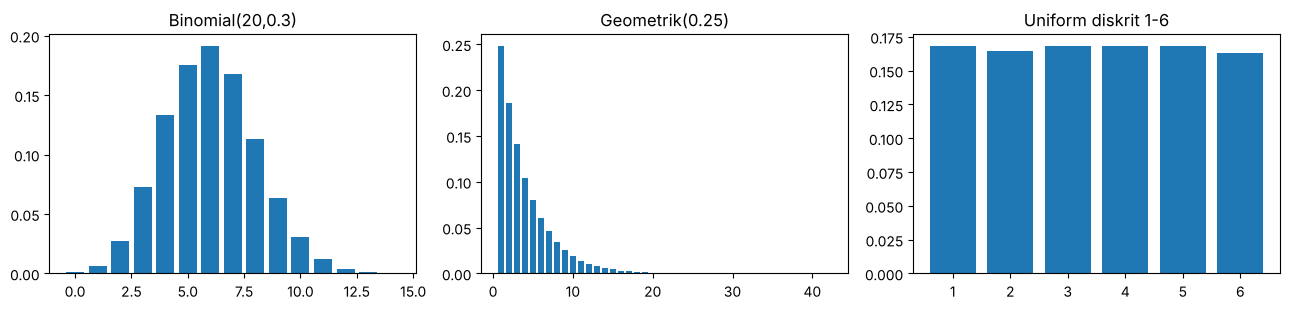

In [8]:
random.seed(9)
N=50_000
# Binomial(20,0.3)
b=[sum(random.random()<.3 for _ in range(20)) for _ in range(N)]
# Geometrik(0.25): percobaan sampai sukses pertama
def geo(p):
    k=1
    while random.random()>=p: k+=1
    return k
g=[geo(.25) for _ in range(N)]
# Uniform diskrit 1..6
u=[random.randint(1,6) for _ in range(N)]
print("Binomial(20,.3): mean",round(st.fmean(b),3),"(6)   var",round(st.pvariance(b),3),"(4.2)")
print("Geometrik(.25) : mean",round(st.fmean(g),3),"(4)   var",round(st.pvariance(g),3),"(12)")
print("Uniform(1..6)  : mean",round(st.fmean(u),3),"(3.5) var",round(st.pvariance(u),3),"(2.9167)")
fig,ax=plt.subplots(1,3,figsize=(13,3.2))
for a,d,t in zip(ax,[b,g,u],["Binomial(20,0.3)","Geometrik(0.25)","Uniform diskrit 1-6"]):
    c=Counter(d); ks=sorted(c); a.bar(ks,[c[k]/N for k in ks]); a.set_title(t)
plt.tight_layout(); plt.show()

**Interpretasi:** Rata-rata dan varians simulasi mendekati rumus teori (np, npq; 1/p, (1−p)/p²; (n+1)/2, (n²−1)/12). Geometrik sangat condong ke kanan sehingga variansnya besar dibanding rata-ratanya.

### Soal 3.4 — Teorema Limit Pusat (CLT)
Mean dari n variabel Uniform(0,1) berdistribusi mendekati Normal(0,5; √(1/12n)) walau distribusi asalnya datar.

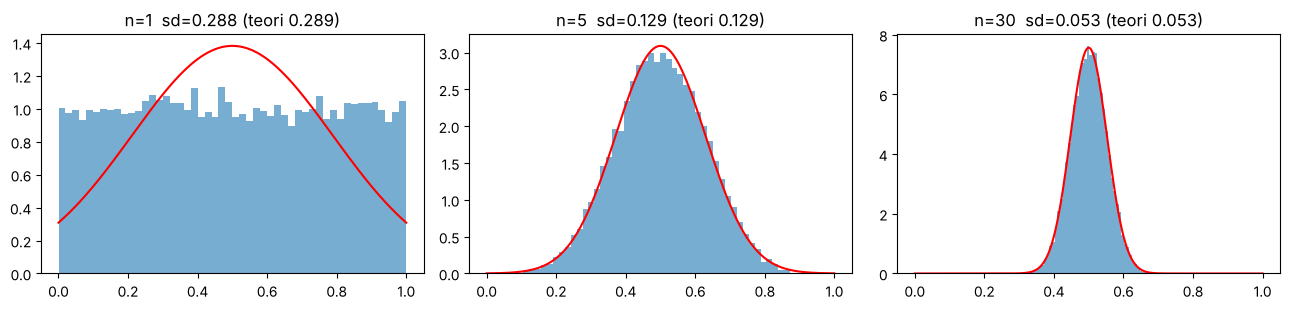

In [9]:
random.seed(4)
fig,ax=plt.subplots(1,3,figsize=(13,3.2))
for a,n in zip(ax,[1,5,30]):
    m=[st.fmean(random.random() for _ in range(n)) for _ in range(20_000)]
    a.hist(m,bins=50,density=True,alpha=.6)
    nd=NormalDist(.5,math.sqrt(1/(12*n))); xs=[i/200 for i in range(201)]
    a.plot(xs,[nd.pdf(x) for x in xs],'r'); a.set_title(f"n={n}  sd={st.stdev(m):.3f} (teori {nd.stdev:.3f})")
plt.tight_layout(); plt.show()

**Interpretasi:** Pada n=1 bentuknya datar; n=5 sudah mulai lonceng; n=30 hampir identik dengan kurva Normal. Inilah dasar mengapa rata-rata waktu respons atau error sering dianalisis dengan Normal.

## 4. Pengembangan Contoh Permasalahan
### Soal 4.1 — Load balancer berbobot (`random.choices`)
Tiga server menerima trafik dengan bobot 5:3:2. Dari 10 request, berapa P(server A menerima ≥ 7)? Simulasikan dan bandingkan dengan Binomial(10, 0,5).

In [10]:
random.seed(6)
N=100_000
cnt=Counter()
tot=Counter()
for _ in range(N):
    r=random.choices("ABC",weights=[5,3,2],k=10)
    cnt[r.count("A")]+=1
p_sim=sum(v for k,v in cnt.items() if k>=7)/N
p_teori=sum(math.comb(10,k)*.5**10 for k in range(7,11))
print("P(A>=7) simulasi:",round(p_sim,4)," teori Binomial:",round(p_teori,4))

P(A>=7) simulasi: 0.1724  teori Binomial: 0.1719


**Interpretasi:** Tiap request memilih A dengan peluang 0,5 secara independen, sehingga jumlah request ke A ~ Binomial(10;0,5) dengan P(≥7)=176/1024≈0,1719. Simulasi cocok → model sudah benar.

### Soal 4.2 — Kebangkrutan penjudi (Gambler's Ruin) — analogi *retry budget*
Sebuah layanan punya "anggaran" 5 poin; tiap request sukses +1 (peluang p) dan gagal −1. Berhenti saat 0 (down) atau 10 (aman). Hitung peluang mencapai 10 dengan p=0,5 dan p=0,45.
**Manual:** P = (1−r^i)/(1−r^N) dengan r=(1−p)/p, i=5, N=10; untuk p=0,5 → i/N = 0,5.

In [11]:
def ruin_sim(p,i=5,N=10,trials=40_000):
    ok=0
    for _ in range(trials):
        x=i
        while 0<x<N: x+= 1 if random.random()<p else -1
        ok+= x==N
    return ok/trials
def ruin_exact(p,i=5,N=10):
    if p==.5: return i/N
    r=(1-p)/p; return (1-r**i)/(1-r**N)
random.seed(11)
for p in (.5,.45,.55):
    print(f"p={p}: teori={ruin_exact(p):.4f}  simulasi={ruin_sim(p):.4f}")

p=0.5: teori=0.5000  simulasi=0.5036
p=0.45: teori=0.2683  simulasi=0.2697


p=0.55: teori=0.7317  simulasi=0.7276


**Interpretasi:** Penurunan peluang sukses hanya 5 poin persentase (0,50→0,45) menurunkan peluang mencapai target dari 50% menjadi ±27%. Sistem yang sedikit "berat sebelah" menimbulkan efek akumulatif besar dalam jangka panjang.

## Kesimpulan
1. `random` + `Counter` cukup untuk simulasi Monte Carlo berbagai masalah (Monty Hall, ulang tahun, Bayes, random walk).
2. `statistics.NormalDist` menggantikan SciPy untuk perhitungan Normal sederhana (CDF, kuantil, z-score).
3. Simulasi selalu mendekati teori, tetapi lambat (loop Python murni). Untuk simulasi jutaan sampel gunakan **NumPy** (notebook 03).